# 8.10 — Numerical Stability and Epoch Batches

**Chapter 8, sections 8.1.4 and 8.3.1.** A companion to 8.4 (logistic regression) and 8.7
(mini-batches).

**The questions this notebook answers:**

1. **Part A.** Why does a logistic-regression run sometimes print a cost of `inf` or `nan`, and how
   is the loss written so that this cannot happen?
2. **Part B.** When a loop trains on mini-batches, how should the batches be chosen, and how is that
   done in Spark without a global shuffle?

Both answers are short. The loss $\log(1+e^{\theta})$ is rewritten so that $e$ is only ever raised to
a number $\le 0$. The batches are drawn in **epochs**: the data are shuffled once per epoch and cut
into $k$ chunks, so every row is used exactly once per epoch. In Spark the "shuffle and cut" is one
narrow pass that tags every row with a random chunk number.

Notation as in the chapter: $\boldsymbol\beta$ is the parameter vector, $\theta_i=x_i^{\top}\boldsymbol\beta$
is the linear predictor (the log-odds) of example $i$, $\sigma(\theta)=1/(1+e^{-\theta})$ is the
sigmoid, and $\eta$ is the learning rate.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))
os.makedirs(SCRATCH, exist_ok=True)

spark = (SparkSession.builder
         .appName("CS777-8.10")
         .master("local[4]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark", spark.version)

Spark 4.2.0


---

# Part A — Numerical stability

## 1. Where $e^{\theta}$ stops being a number

A computer stores a real number as a 64-bit double, and the largest double is about
$1.8\times10^{308}$. Since $\log(1.8\times10^{308})\approx 709.8$, the exponential $e^{\theta}$
cannot be stored for any $\theta$ above about 709. The result is called an **overflow**. What
happens then depends on the library: NumPy returns `inf` and prints a warning, while Python's own
`math.exp` stops with an `OverflowError`.

In [2]:
print("largest double      :", np.finfo(np.float64).max)
print("its natural log     :", np.log(np.finfo(np.float64).max))
print("np.exp(709)         :", np.exp(709.0))
print("np.exp(710)         :", np.exp(710.0))          # overflows: inf, with a RuntimeWarning

try:
    math.exp(710)
except OverflowError as err:
    print("math.exp(710)       : OverflowError:", err)

largest double      : 1.7976931348623157e+308
its natural log     : 709.782712893384
np.exp(709)         : 8.218407461554972e+307
np.exp(710)         : inf
math.exp(710)       : OverflowError: math range error


/var/folders/wh/ptq7zytj1gz42sqc0rs52tm40000gn/T/ipykernel_88407/1519860162.py:4: RuntimeWarning: overflow encountered in exp
  print("np.exp(710)         :", np.exp(710.0))          # overflows: inf, with a RuntimeWarning


## 2. What an infinity does to the loss

The per-example logistic loss, as the chapter writes it, is

$$\ell_i = -y_i\theta_i + \log\bigl(1+e^{\theta_i}\bigr).$$

For $\theta_i = 800$ the exponential is `inf`, so the loss is `inf` — although the true value is a
perfectly ordinary number (for $y_i=1$ it is almost exactly 0, for $y_i=0$ it is almost exactly 800).

An infinity does not stay alone for long. Arithmetic that has no defined answer —
$\infty-\infty$, $\infty/\infty$, $0\cdot\infty$ — gives `nan`, *not a number*. The gradient form
used in 8.4, $e^{\theta}/(1+e^{\theta})$, is exactly such an expression.

In [3]:
theta = 800.0
with np.errstate(over="ignore", invalid="ignore"):          # the warnings were shown above
    print("log(1 + e^800)      :", np.log(1 + np.exp(theta)))
    print("loss for y=1        :", -1 * theta + np.log(1 + np.exp(theta)))
    print("inf - inf           :", np.inf - np.inf)
    print("inf / inf           :", np.inf / np.inf)
    print("0 * inf             :", 0 * np.inf)
    print("e^800 / (1 + e^800) :", np.exp(theta) / (1 + np.exp(theta)), "  <- the sigmoid as 8.4 writes it")

log(1 + e^800)      : inf
loss for y=1        : inf
inf - inf           : nan
inf / inf           : nan
0 * inf             : nan
e^800 / (1 + e^800) : nan   <- the sigmoid as 8.4 writes it


## 3. The cross-entropy form fails much earlier

The same loss is often written as the cross-entropy

$$\ell_i = -y_i\log\sigma(\theta_i) - (1-y_i)\log\bigl(1-\sigma(\theta_i)\bigr).$$

It is mathematically identical, but numerically it is worse. A double carries about 16 significant
digits, so once $\sigma(\theta)$ is within $10^{-16}$ of 1 it is stored as *exactly* 1.0, and
$1-\sigma(\theta)$ becomes exactly 0. That happens already near $\theta=37$, far below 709.

In [4]:
sigmoid_naive = lambda t: 1.0 / (1.0 + np.exp(-t))

for t in (35.0, 36.0, 37.0, 38.0):
    print(f"theta = {t:4.0f}   1 - sigma(theta) = {1 - sigmoid_naive(t):.3e}")

with np.errstate(divide="ignore", invalid="ignore"):
    s = sigmoid_naive(37.0)
    print("\nlog(1 - sigma(37))            :", np.log(1 - s))
    print("cross-entropy, y=0, theta=37  :", -0 * np.log(s) - (1 - 0) * np.log(1 - s), "  (true value is about 37)")
    print("cross-entropy, y=1, theta=37  :", -1 * np.log(s) - (1 - 1) * np.log(1 - s), "  (true value is about 1e-16)")

theta =   35   1 - sigma(theta) = 6.661e-16
theta =   36   1 - sigma(theta) = 2.220e-16
theta =   37   1 - sigma(theta) = 0.000e+00
theta =   38   1 - sigma(theta) = 0.000e+00

log(1 - sigma(37))            : -inf
cross-entropy, y=0, theta=37  : inf   (true value is about 37)
cross-entropy, y=1, theta=37  : nan   (true value is about 1e-16)


The last line is worth reading twice. For $y=1$ the model is *right*, and the loss should be tiny.
It is `nan`, because the formula multiplies $(1-y)=0$ by $\log 0=-\infty$.

## 4. When large $\theta$ happens, and why one row is enough

Values of $|\theta_i|$ in the tens or hundreds are not exotic:

* **An outlying feature.** A standardized feature measures distance from the mean in standard
  deviations. Most values lie within $\pm 3$, but in a large dataset a few rows lie 10 or more
  standard deviations out.
* **A learning rate that is too large.** While $\eta$ is being searched for, a rate that is too
  large makes $\boldsymbol\beta$ *grow* at every iteration, and $\theta_i=x_i^{\top}\boldsymbol\beta$
  grows with it.
* **Class weights** (8.5) multiply the gradient of the rare class, so they enlarge the steps in the
  same way.

And the damage is not local. The cost is a **sum** over rows, and the gradient is a sum over rows, so
a single `inf` or `nan` anywhere makes the whole sum `inf` or `nan`. After one update every parameter
is `nan`, and so is every later cost. The run can no longer be told apart from a crash.

The cell below shows it on five rows. Four are ordinary; the fifth has a first feature 12 standard
deviations out, and the parameters are those a diverging run might have reached.

In [5]:
X5 = np.array([[1.0,  0.3, -1.2],       # columns: intercept, x1, x2
               [1.0, -0.8,  0.4],
               [1.0,  1.1,  0.9],
               [1.0, -0.2, -0.5],
               [1.0, 12.0,  0.1]])      # an outlier: x1 is 12 standard deviations out
y5 = np.array([1.0, 0.0, 1.0, 0.0, 0.0])
beta_big = np.array([-1.0, 60.0, -1.0])

with np.errstate(over="ignore", invalid="ignore"):
    theta5 = X5 @ beta_big
    print("theta_i        :", theta5)
    loss5 = -y5 * theta5 + np.log(1 + np.exp(theta5))
    print("per-row loss   :", loss5)
    print("total cost     :", loss5.sum())

    grad5 = X5.T @ (np.exp(theta5) / (1 + np.exp(theta5)) - y5)     # 8.4's form of sigma
    beta_next = beta_big - 0.1 * grad5
    print("gradient       :", grad5)
    print("beta after step:", beta_next)
    print("next cost      :", (-y5 * (X5 @ beta_next) + np.log(1 + np.exp(X5 @ beta_next))).sum())

theta_i        : [ 18.2 -49.4  64.1 -12.5 718.9]
per-row loss   : [1.24692541e-08 0.00000000e+00 0.00000000e+00 3.72664623e-06
            inf]
total cost     : inf
gradient       : [nan nan nan]
beta after step: [nan nan nan]
next cost      : nan


## 5. The fix: never raise $e$ to a positive number

Factor $e^{\max(\theta,0)}$ out of $1+e^{\theta}$. For $\theta\ge0$,
$1+e^{\theta}=e^{\theta}\bigl(e^{-\theta}+1\bigr)$; for $\theta<0$ nothing needs factoring. Both
cases are one identity:

$$\log\bigl(1+e^{\theta}\bigr) = \max(\theta,0) + \log\bigl(1+e^{-|\theta|}\bigr).$$

Now the exponent $-|\theta|$ is never positive, so $e^{-|\theta|}$ lies in $(0,1]$ and cannot
overflow. The stable per-example loss is

$$\ell_i = -y_i\theta_i + \max(\theta_i,0) + \log\bigl(1+e^{-|\theta_i|}\bigr).$$

Two refinements complete it:

* **`log1p`.** When $e^{-|\theta|}$ is tiny, $1+e^{-|\theta|}$ rounds to 1 and its logarithm to 0.
  `log1p(z)` computes $\log(1+z)$ without forming $1+z$, so it stays accurate for tiny $z$.
* **A two-branch sigmoid** for the gradient. For $\theta\ge0$ use $1/(1+e^{-\theta})$; for
  $\theta<0$ use $e^{\theta}/(1+e^{\theta})$. Each branch raises $e$ only to a non-positive power.

In [6]:
def log1pexp_naive(t):
    return np.log(1 + np.exp(t))

def log1pexp_stable(t):
    return np.maximum(t, 0) + np.log1p(np.exp(-np.abs(t)))

def sigmoid_stable(t):
    t = np.asarray(t, dtype=float)
    e = np.exp(-np.abs(t))                      # always in (0, 1]
    return np.where(t >= 0, 1 / (1 + e), e / (1 + e))


thetas = np.array([-800, -40, -37, -5, 0, 5, 36, 37, 40, 709, 710, 800], dtype=float)
with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
    table = pd.DataFrame({
        "theta": thetas,
        "log(1+e^t) naive": log1pexp_naive(thetas),
        "log(1+e^t) stable": log1pexp_stable(thetas),
        "sigma naive (8.4 form)": np.exp(thetas) / (1 + np.exp(thetas)),
        "sigma stable": sigmoid_stable(thetas),
        "1 - sigma stable": 1 - sigmoid_stable(thetas),
    })
pd.set_option("display.width", 140)
print(table.to_string(index=False))

 theta  log(1+e^t) naive  log(1+e^t) stable  sigma naive (8.4 form)  sigma stable  1 - sigma stable
-800.0          0.000000       0.000000e+00            0.000000e+00  0.000000e+00      1.000000e+00
 -40.0          0.000000       4.248354e-18            4.248354e-18  4.248354e-18      1.000000e+00
 -37.0          0.000000       8.533048e-17            8.533048e-17  8.533048e-17      1.000000e+00
  -5.0          0.006715       6.715348e-03            6.692851e-03  6.692851e-03      9.933071e-01
   0.0          0.693147       6.931472e-01            5.000000e-01  5.000000e-01      5.000000e-01
   5.0          5.006715       5.006715e+00            9.933071e-01  9.933071e-01      6.692851e-03
  36.0         36.000000       3.600000e+01            1.000000e+00  1.000000e+00      2.220446e-16
  37.0         37.000000       3.700000e+01            1.000000e+00  1.000000e+00      0.000000e+00
  40.0         40.000000       4.000000e+01            1.000000e+00  1.000000e+00      0.000000e+00


Read the table by column. Wherever the naive column is finite, the stable one agrees with it; where
the naive column is `inf` or `nan`, the stable one gives the right answer ($\log(1+e^{800})=800$ to
every digit a double can hold). The next cell checks the agreement rather than claiming it.

The last column shows a limit that no rewriting of $\sigma$ removes: $1-\sigma(40)$ is still exactly 0,
because $\sigma(40)$ is stored as 1.0. That is why the loss must be computed from $\theta$ directly,
through $\log(1+e^{\theta})$, and **never** as $\log(1-\sigma(\theta))$ from an already-rounded
probability.

In [7]:
with np.errstate(over="ignore", invalid="ignore"):
    naive_l = log1pexp_naive(thetas)
    naive_s = np.exp(thetas) / (1 + np.exp(thetas))
ok_l, ok_s = np.isfinite(naive_l), np.isfinite(naive_s)
assert np.allclose(naive_l[ok_l], log1pexp_stable(thetas)[ok_l], rtol=1e-12)
assert np.allclose(naive_s[ok_s], sigmoid_stable(thetas)[ok_s], rtol=1e-12)
assert np.all(np.isfinite(log1pexp_stable(thetas))) and np.all(np.isfinite(sigmoid_stable(thetas)))
print(f"loss   : equal on the {ok_l.sum()} finite naive values, finite on all {len(thetas)}")
print(f"sigmoid: equal on the {ok_s.sum()} finite naive values, finite on all {len(thetas)}")

loss   : equal on the 10 finite naive values, finite on all 12
sigmoid: equal on the 10 finite naive values, finite on all 12


## 6. The same fix in Spark

The data for the rest of the notebook: twenty thousand rows drawn from a logistic model with two
standardized features, $\theta = -1 + 2x_1 - x_2$. The rows are stored **sorted by $x_1$** — the way a
file of trips is usually stored sorted by time — which Part B will need.

Section 4's outlier is appended as one extra row, in a separate copy, so the damage it does can be
seen at scale.

In [8]:
N, K = 20_000, 10
rng = np.random.default_rng(777)
x1, x2 = rng.standard_normal(N), rng.standard_normal(N)
p = 1 / (1 + np.exp(-(-1 + 2 * x1 - x2)))
label = (rng.random(N) < p).astype(float)

pdf = pd.DataFrame({"x1": x1, "x2": x2, "y": label}).sort_values("x1").reset_index(drop=True)
pdf.insert(0, "id", np.arange(N))                  # the row's position in the sorted file

COLS = ["one", "x1", "x2"]                         # parameter order: intercept first
df = spark.createDataFrame(pdf).withColumn("one", F.lit(1.0)).cache()   # 4 partitions, file order kept
rdd = df.rdd.map(lambda r: (r["y"], np.array([1.0, r["x1"], r["x2"]]))).cache()
print("rows:", df.count(), "  RDD rows:", rdd.count(), "  partitions:", df.rdd.getNumPartitions(),
      "  positive rate:", round(label.mean(), 4))

outlier = spark.createDataFrame([(N, 12.0, 0.1, 0.0)], ["id", "x1", "x2", "y"]).withColumn("one", F.lit(1.0))
df_out = df.unionByName(outlier).cache()
rdd_out = rdd.union(sc.parallelize([(0.0, np.array([1.0, 12.0, 0.1]))])).cache()
print("with the outlier:", df_out.count(), "rows")

rows: 20000   RDD rows: 20000   partitions: 4   positive rate: 0.3662
with the outlier: 20001 rows


**On the RDD**, the per-example work lives in the `seqOp` of `treeAggregate`, so the stable loss
and the two-branch sigmoid go there. The accumulator is the chapter's triple: summed loss, summed
gradient, count. The division by the count happens on the driver.

In [9]:
def add3(a, b):
    return a[0] + b[0], a[1] + b[1], a[2] + b[2]

def log_pass_rdd(data, beta):
    # One pass: (summed loss, summed gradient, count), computed stably.
    def seq(acc, pair):
        y, x = pair
        t = float(np.dot(x, beta))
        loss = -y * t + max(t, 0.0) + np.log1p(np.exp(-abs(t)))
        sig = 1 / (1 + np.exp(-t)) if t >= 0 else np.exp(t) / (1 + np.exp(t))
        return acc[0] + loss, acc[1] + x * (sig - y), acc[2] + 1
    return data.treeAggregate((0.0, np.zeros(len(beta)), 0), seq, add3)

def log_pass_rdd_naive(data, beta):
    # The same pass with 8.4's arithmetic, for comparison only.
    def seq(acc, pair):
        y, x = pair
        t = float(np.dot(x, beta))
        return (acc[0] - y * t + np.log(1 + np.exp(t)),
                acc[1] + x * (np.exp(t) / (1 + np.exp(t)) - y), acc[2] + 1)
    return data.treeAggregate((0.0, np.zeros(len(beta)), 0), seq, add3)


for name, fn in (("naive ", log_pass_rdd_naive), ("stable", log_pass_rdd)):
    loss, grad, n = fn(rdd_out, beta_big)
    print(f"{name}  cost = {loss / n:.6f}   gradient = {grad / n}")

naive   cost = inf   gradient = [nan nan nan]
stable  cost = 7.964835   gradient = [0.12980159 0.13673813 0.13108955]


/var/folders/wh/ptq7zytj1gz42sqc0rs52tm40000gn/T/ipykernel_88407/1265744800.py:19: RuntimeWarning: overflow encountered in exp
/var/folders/wh/ptq7zytj1gz42sqc0rs52tm40000gn/T/ipykernel_88407/1265744800.py:20: RuntimeWarning: overflow encountered in exp
/var/folders/wh/ptq7zytj1gz42sqc0rs52tm40000gn/T/ipykernel_88407/1265744800.py:20: RuntimeWarning: invalid value encountered in scalar divide


**On the DataFrame**, the same arithmetic is a column expression: `F.greatest` for the maximum,
`F.abs`, `F.exp`, `F.log1p`, and `F.when` for the two branches of the sigmoid. No UDF is needed, so
nothing leaves the JVM. $\theta$ is built from `F.lit` values of the current $\boldsymbol\beta$, as in 8.8.

In [10]:
def theta_expr(beta):
    return sum(F.lit(float(b)) * F.col(c) for b, c in zip(beta, COLS))

def log_pass_df(data, beta):
    t, y = theta_expr(beta), F.col("y")
    loss = -y * t + F.greatest(t, F.lit(0.0)) + F.log1p(F.exp(-F.abs(t)))
    sig = F.when(t >= 0, 1 / (1 + F.exp(-t))).otherwise(F.exp(t) / (1 + F.exp(t)))
    row = data.agg(F.sum(loss).alias("loss"), F.count(F.lit(1)).alias("n"),
                   *[F.sum((sig - y) * F.col(c)).alias(c) for c in COLS]).first()
    return row["loss"], np.array([row[c] for c in COLS]), row["n"]


loss_d, grad_d, n_d = log_pass_df(df_out, beta_big)
loss_r, grad_r, n_r = log_pass_rdd(rdd_out, beta_big)
print(f"DataFrame cost = {loss_d / n_d:.6f}   gradient = {grad_d / n_d}")
assert n_d == n_r and np.isclose(loss_d, loss_r) and np.allclose(grad_d, grad_r)
print("RDD and DataFrame passes agree.")

DataFrame cost = 7.964835   gradient = [0.12980159 0.13673813 0.13108955]
RDD and DataFrame passes agree.


For contrast, the two naive forms written as Spark SQL. Spark follows the same floating-point rules
as NumPy, so the first is `Infinity` and the gradient term is `NaN`. The cross-entropy form fails in a
different, quieter way: **Spark's `log` returns `NULL`** (not $-\infty$) for an argument of 0, and
`F.sum` skips `NULL`s. The sum therefore comes back as an ordinary-looking number that silently leaves
out every row with $|\theta_i| \gtrsim 37$ — the rows that matter most.

In [11]:
t, y = theta_expr(beta_big), F.col("y")
sig_n = 1 / (1 + F.exp(-t))
naive_forms = df_out.agg(
    F.sum(-y * t + F.log(1 + F.exp(t))).alias("naive log(1+e^t)"),
    F.sum(F.exp(t) / (1 + F.exp(t)) - y).alias("naive sigma - y"),
    F.sum(-y * F.log(sig_n) - (1 - y) * F.log(1 - sig_n)).alias("cross-entropy"),
    F.count(F.when((-y * F.log(sig_n) - (1 - y) * F.log(1 - sig_n)).isNull(), 1)).alias("rows it dropped"),
    F.sum(-y * t + F.greatest(t, F.lit(0.0)) + F.log1p(F.exp(-F.abs(t)))).alias("stable"))
naive_forms.show(truncate=False)

+----------------+---------------+----------------+---------------+------------------+
|naive log(1+e^t)|naive sigma - y|cross-entropy   |rows it dropped|stable            |
+----------------+---------------+----------------+---------------+------------------+
|Infinity        |NaN            |78021.4292147542|5390           |159304.66943600646|
+----------------+---------------+----------------+---------------+------------------+



---

# Part B — Mini-batch training by epochs

## 7. Three ways to choose the batches

* **Full batch.** Every iteration uses all $n$ rows. The gradient is exact, and each iteration costs a
  full pass of arithmetic.
* **An independent sample per iteration**, as in 8.7: `sample(False, f, seed=i)`. Each iteration
  sees about $fn$ rows, but the samples are independent, so some rows are drawn several times and
  others never.
* **Epochs.** At the start of every epoch the data are shuffled and cut into $k$ consecutive chunks;
  iteration $j$ of the epoch trains on chunk $j$. Every row is used **exactly once per epoch**, and
  $k$ iterations make one epoch. This is the standard algorithm in every deep-learning library.

How uneven is independent sampling? Ten iterations at $f=0.1$ draw about as many rows as there are
in total. If the draws were an epoch, every row would be used once. With independent draws, each row
is left out of each sample with probability $0.9$, so it is never used with probability
$0.9^{10}\approx 0.35$. The cell below measures it.

In [12]:
f, iters = 0.1, 10
drawn = None
for i in range(iters):
    s = df.sample(False, f, seed=i).select("id")
    drawn = s if drawn is None else drawn.unionAll(s)

uses = drawn.groupBy("id").count()
distinct_seen = uses.count()
used = uses.groupBy(F.col("count").alias("times used")).count().toPandas().set_index("times used")["count"]
used.loc[0] = N - distinct_seen
used = used.sort_index()

from math import comb
expected = [N * comb(iters, k) * f**k * (1 - f)**(iters - k) for k in used.index]
print(pd.DataFrame({"rows": used, "expected (binomial)": np.round(expected).astype(int)}).to_string())
print(f"\nrows drawn in total : {int((used * used.index).sum())}   (n = {N})")
print(f"distinct rows seen  : {distinct_seen} of {N}  ({distinct_seen / N:.1%})")
print(f"never used          : {N - distinct_seen}  ({(N - distinct_seen) / N:.1%};  0.9^10 = {0.9**10:.1%})")

            rows  expected (binomial)
times used                           
0           6897                 6974
1           7860                 7748
2           3897                 3874
3           1112                 1148
4            201                  223
5             29                   30
6              3                    3
7              1                    0

rows drawn in total : 19964   (n = 20000)
distinct rows seen  : 13103 of 20000  (65.5%)
never used          : 6897  (34.5%;  0.9^10 = 34.9%)


About a third of the data was never looked at, while a quarter was used twice or more. In an epoch
of ten chunks, every one of the twenty thousand rows would have been used exactly once.

## 8. Why shuffle, and why again every epoch

If the chunks were cut in file order, each batch would be a contiguous slice of a sorted file. Files
usually *are* sorted — by time, by customer, by whatever they were written in. Here the file is
sorted by $x_1$, and $x_1$ drives the label, so consecutive slices have wildly different class
balances. Every step would then pull $\boldsymbol\beta$ towards a different, unrepresentative
batch. A random chunk assignment gives every chunk the same balance as the whole.

In [13]:
consecutive = df.withColumn("chunk", (F.col("id") * K / N).cast("int"))
randomized = df.withColumn("chunk", (F.rand(seed=777) * K).cast("int"))

rates = pd.DataFrame({
    "consecutive: positive rate": consecutive.groupBy("chunk").agg(F.avg("y")).toPandas().set_index("chunk").iloc[:, 0],
    "random chunks: positive rate": randomized.groupBy("chunk").agg(F.avg("y")).toPandas().set_index("chunk").iloc[:, 0],
}).sort_index().round(3)
print(rates.to_string())
print("\nwhole data:", round(label.mean(), 3))

       consecutive: positive rate  random chunks: positive rate
chunk                                                          
0                           0.024                         0.380
1                           0.067                         0.351
2                           0.128                         0.359
3                           0.180                         0.350
4                           0.276                         0.378
5                           0.363                         0.356
6                           0.453                         0.375
7                           0.578                         0.366
8                           0.712                         0.390
9                           0.881                         0.358

whole data: 0.366


Reshuffling every epoch matters for a subtler reason. With a fixed cut, the model would see the same
ten batches in the same order forever, and the last batch of every epoch would always be the same
one. A fresh shuffle per epoch changes both the composition and the order of the batches, so no
fixed pattern in them can steer the parameters.

## 9. The shuffle and the cut in one pass, on the DataFrame

A true shuffle, `orderBy(F.rand())`, sorts the whole dataset across the cluster — a wide
transformation with an exchange. It is not needed. Giving every row the chunk number
$\lfloor k\,u \rfloor$, with $u$ uniform on $[0,1)$, *is* a random cut into $k$ chunks, and it is a
narrow, per-row computation.

* $u$ comes from `F.rand(seed=777 + e)`, so each epoch $e$ gets a different, reproducible assignment.
* The tagged data are **cached** once per epoch. Each of the $k$ iterations then filters the cached
  copy for its chunk instead of re-reading and re-tagging the source.
* When the next epoch starts, the previous epoch's tagged copy is **unpersisted**, so only one copy is
  ever held in memory.

`F.rand` is deterministic for a given seed *and a given partitioning*; the source DataFrame is cached,
so its partitioning does not change between epochs.

In [14]:
def tag_epoch_df(data, e, k=K):
    return data.withColumn("chunk", (F.rand(seed=777 + e) * k).cast("int"))

import io, contextlib
def plan_of(d):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        d.explain()
    return buf.getvalue()

print("tagging with F.rand has an Exchange (shuffle):", "Exchange" in plan_of(tag_epoch_df(df, 0)))
print("orderBy(F.rand) has an Exchange (shuffle)    :", "Exchange" in plan_of(df.orderBy(F.rand(seed=777))))

tagging with F.rand has an Exchange (shuffle): False
orderBy(F.rand) has an Exchange (shuffle)    : True


Now check the three properties the epoch promises: the chunks are **disjoint**, together they
**cover** every row, and their sizes are close to $n/k$ but not equal (the assignment is random, so
the sizes vary by a few percent — which does not matter).

In [15]:
tagged0 = tag_epoch_df(df, 0).cache()
sizes = [tagged0.filter(F.col("chunk") == j).count() for j in range(K)]
print("chunk sizes   :", sizes, "  sum =", sum(sizes))

ids = tagged0.select("id", "chunk")
covered = ids.select("id").distinct().count()
assert sum(sizes) == N == covered                  # every row in exactly one chunk
assert set(r["chunk"] for r in ids.select("chunk").distinct().collect()) == set(range(K))
print("disjoint and covering: every one of", N, "rows is in exactly one chunk")
print(f"sizes vary from {min(sizes)} to {max(sizes)} around n/k = {N // K}")

chunk sizes   : [2002, 1945, 2042, 1947, 1984, 2017, 1999, 2062, 1944, 2058]   sum = 20000
disjoint and covering: every one of 20000 rows is in exactly one chunk
sizes vary from 1944 to 2062 around n/k = 2000


In [16]:
tagged1 = tag_epoch_df(df, 1).cache()
same = (tagged0.select("id", F.col("chunk").alias("c0"))
               .join(tagged1.select("id", F.col("chunk").alias("c1")), "id")
               .filter("c0 = c1").count())
print(f"rows in the same chunk in epochs 0 and 1: {same} of {N} ({same / N:.1%}; chance alone = 1/k = {1 / K:.0%})")
tagged0.unpersist(); tagged1.unpersist();

rows in the same chunk in epochs 0 and 1: 1990 of 20000 (10.0%; chance alone = 1/k = 10%)


## 10. The same on the RDD

An RDD has no `F.rand`, so each partition draws its own random numbers with a NumPy generator. The
seed combines the epoch and the partition index — `default_rng((777 + e) * 100003 + idx)` — so that
partitions do not repeat each other's sequence and every epoch differs. `mapPartitionsWithIndex`
supplies the index, and the output pairs are `(chunk, record)`.

In [17]:
def tag_epoch_rdd(data, e, k=K):
    def tag(idx, rows):
        g = np.random.default_rng((777 + e) * 100003 + idx)
        for r in rows:
            yield int(g.integers(k)), r
    return data.mapPartitionsWithIndex(tag)


t0 = tag_epoch_rdd(rdd, 0).cache()
sizes_rdd = [t0.filter(lambda kv, j=j: kv[0] == j).count() for j in range(K)]
print("chunk sizes:", sizes_rdd, "  sum =", sum(sizes_rdd))
assert sum(sizes_rdd) == N and set(t0.keys().distinct().collect()) == set(range(K))

# Each record carries exactly one tag, so the chunks are disjoint by construction;
# the sum above shows they cover the data. Now compare two epochs, record by record.
t1 = tag_epoch_rdd(rdd, 1)
k0, k1 = np.array(t0.keys().collect()), np.array(t1.keys().collect())
print(f"same chunk in epochs 0 and 1: {(k0 == k1).mean():.1%} of rows")
t0.unpersist();

chunk sizes: [2008, 2030, 2046, 1905, 1969, 2023, 2018, 1966, 2029, 2006]   sum = 20000


same chunk in epochs 0 and 1: 10.1% of rows


## 11. Training by epochs

The batch function below hides the epoch bookkeeping. Iteration $i$ belongs to epoch
$e=\lfloor i/k\rfloor$ and uses chunk $j = i \bmod k$. When $e$ changes, the previous epoch's tagged
copy is unpersisted and a new one is tagged, cached and materialized. The training loop itself is the
chapter's mini-batch loop and does not know how the batches were made.

The learning rate is fixed, and the cost printed is the **batch** cost — the average loss over the
chunk just used, which is free because the pass computes it anyway. It is noisy, since each chunk is
a different tenth of the data, but its trend is the convergence check.

In [18]:
def epoch_batches(data, is_rdd, k=K):
    state = {"e": None, "tagged": None}
    def batch(i):
        e, j = divmod(i, k)
        if e != state["e"]:                               # a new epoch: re-tag, cache, drop the old one
            if state["tagged"] is not None:
                state["tagged"].unpersist()
            tagged = tag_epoch_rdd(data, e, k) if is_rdd else tag_epoch_df(data, e, k)
            tagged = tagged.cache()
            tagged.count()
            state["e"], state["tagged"] = e, tagged
        if is_rdd:
            return state["tagged"].filter(lambda kv, j=j: kv[0] == j).values()
        return state["tagged"].filter(F.col("chunk") == j)
    return batch


def minibatch_descent(pass_fn, batch_fn, eta, iterations):
    beta, costs = np.zeros(len(COLS)), []
    for i in range(iterations):
        loss, grad, n = pass_fn(batch_fn(i), beta)
        costs.append(loss / n)
        beta = beta - eta * grad / n
    return beta, costs

In [19]:
ETA, EPOCHS = 1.0, 3                    # a generic rate for this synthetic, standardized data
ITERS = EPOCHS * K

t = time.perf_counter()
beta_df, costs_df = minibatch_descent(log_pass_df, epoch_batches(df, is_rdd=False), ETA, ITERS)
secs_epoch_df = time.perf_counter() - t

t = time.perf_counter()
beta_rdd, costs_rdd = minibatch_descent(log_pass_rdd, epoch_batches(rdd, is_rdd=True), ETA, ITERS)
secs_epoch_rdd = time.perf_counter() - t

print("true beta          : [-1.  2. -1.]")
print("DataFrame, epochs  :", beta_df.round(4), f"  {secs_epoch_df:.1f} s")
print("RDD, epochs        :", beta_rdd.round(4), f"  {secs_epoch_rdd:.1f} s")

true beta          : [-1.  2. -1.]
DataFrame, epochs  : [-0.871   1.7299 -0.8848]   2.2 s
RDD, epochs        : [-0.8622  1.737  -0.8855]   0.6 s


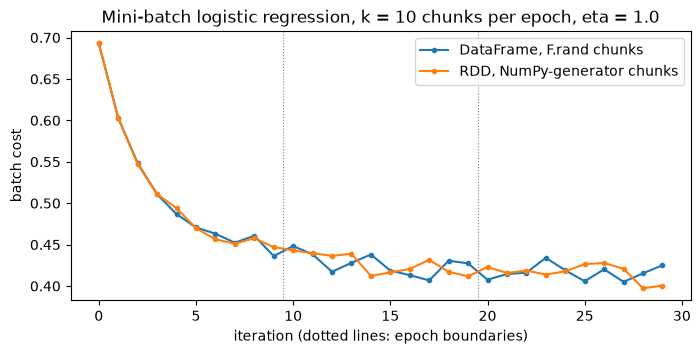

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(costs_df, marker=".", label="DataFrame, F.rand chunks")
ax.plot(costs_rdd, marker=".", label="RDD, NumPy-generator chunks")
for e in range(1, EPOCHS):
    ax.axvline(e * K - 0.5, color="grey", lw=0.8, ls=":")
ax.set_xlabel("iteration (dotted lines: epoch boundaries)")
ax.set_ylabel("batch cost")
ax.set_title(f"Mini-batch logistic regression, k = {K} chunks per epoch, eta = {ETA}")
ax.legend()
plt.show()

The two curves are not identical — the RDD and the DataFrame draw their random chunks from different
generators, so they see different batches — but they fall together and level off, and both
parameter vectors move toward the true $(-1, 2, -1)$. Three epochs at a fixed rate do not reach it
exactly; more epochs would move them further, at the price of more passes.

## 12. Epochs against independent samples, at the same budget

The same loop with 8.7's batches: `sample(False, 1/k, seed=i)` at every iteration, so both runs
process about the same number of rows. The comparison uses the **full-data** cost of the final
parameters (one extra stable pass) so that both are judged on the same rows.

In [21]:
sample_batches = lambda i: df.sample(False, 1 / K, seed=i)

t = time.perf_counter()
beta_smp, costs_smp = minibatch_descent(log_pass_df, sample_batches, ETA, ITERS)
secs_sample_df = time.perf_counter() - t

def full_cost(beta):
    loss, _, n = log_pass_df(df, beta)
    return loss / n

rows = [("epochs", beta_df, secs_epoch_df), ("independent samples", beta_smp, secs_sample_df)]
print(pd.DataFrame([{"batches": name, "beta": np.round(b, 4), "full-data cost": round(full_cost(b), 5),
                     "seconds": round(s, 2)} for name, b, s in rows]).to_string(index=False))
print(f"\nepochs took {secs_epoch_df / secs_sample_df:.2f} x the time of independent samples   (timings are machine-dependent)")

            batches                       beta  full-data cost  seconds
             epochs  [-0.871, 1.7299, -0.8848]         0.41409     2.16
independent samples [-0.8718, 1.7228, -0.8822]         0.41419     1.59

epochs took 1.36 x the time of independent samples   (timings are machine-dependent)


At this size the two batch schemes reach almost the same parameters and the same full-data cost, so
the comparison is not about accuracy on a toy problem. Nor are epochs a way to save time: each
epoch adds one tagging-and-caching job, and each iteration's filter on the cached copy is still a
scan of the whole copy, just as `sample` scans the whole dataset (8.7). The printed ratio is the
price of that extra job on this machine.

What the epochs buy is **coverage**. Section 7 showed independent sampling leaving about a third of
the rows unused over ten iterations; every epoch here used each of the twenty thousand rows exactly
once. On real data — where the rare, informative rows are the ones a sample is most likely to miss
— that guarantee is the reason epochs are the standard.

---

## Conclusion

**Stability.** $e^{\theta}$ overflows above $\theta\approx709$; the cross-entropy form breaks near
$\theta\approx37$, where $1-\sigma(\theta)$ rounds to 0. One such row makes the summed cost `inf`,
the gradient `nan`, and every parameter after the next step `nan`. Writing
$\log(1+e^{\theta}) = \max(\theta,0)+\operatorname{log1p}(e^{-|\theta|})$ and using a two-branch
sigmoid raises $e$ only to non-positive powers, agrees with the naive formula wherever that formula
works, and stays finite everywhere. In Spark it is a few lines inside the `seqOp` of `treeAggregate`,
or a column expression built from `F.greatest`, `F.abs`, `F.exp`, `F.log1p` and `F.when` — and on a
DataFrame the naive cross-entropy form is worse than an error, because `log(0)` is `NULL` and
`F.sum` quietly drops the row.

**Epochs.** An independent sample per iteration uses some rows repeatedly and others never. An epoch
shuffles once and cuts the data into $k$ disjoint chunks, so every row is used once per epoch and
$k$ iterations make one epoch. In Spark the shuffle and the cut are a single narrow pass that tags
each row with $\lfloor k u\rfloor$, seeded by the epoch; the tagged data are cached for the epoch
and the previous epoch's copy is released.

In [22]:
df_out.unpersist(); rdd_out.unpersist()
spark.stop()